# Benchmarking Network Inference Methods on Transient Data

This notebook compares multiple methods on transient biological time-series data.


In [3]:
import numpy as np
import graph_tool.all as gt
import sys
import os
import subprocess
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error, roc_curve, precision_recall_curve, auc
from scipy.stats import spearmanr



# Add the parent directory to sys.path so we can import our modules and gene_expr

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), os.pardir)))

from inference_pipeline.data_generation.network_generator import generate_scale_free_W
from inference_pipeline.data_generation.simulator import simulate_realistic_pairs
from inference_pipeline.inference.mcmc_engine import run_burn_in, run_posterior_sampling, compute_ensemble_stats
from inference_pipeline.inference.metrics import plot_probabilistic_network, plot_inferred_vs_true_am, compute_reconstruction_metrics
from inference_pipeline.prediction.export_utils import export_ensemble_to_bin, export_true_to_bin
from gene_expr import GeneExprBlockState


In [ ]:
N = 10
m = 1
seed = 42
seeds_network = np.random.RandomState(seed).randint(0, 10000, size=5)
dt_vals = np.arange(0.1, 1.51, 0.1) # 5 points for dt

dt_sim = 0.005
M_train = 100
t_window = (0.0, 3.0)

mean_d = 0.5
mean_V = 2.0
D_base = 0.02

In [15]:
import pandas as pd
from tqdm.notebook import tqdm
import time
import os

def calc_all_metrics(y_true_binary, y_true_continuous, y_scores, y_inferred_continuous=None):
    mask = ~np.eye(N, dtype=bool)
    y_true_b = y_true_binary[mask]
    y_s = y_scores[mask]
    
    fpr, tpr, _ = roc_curve(y_true_b, y_s)
    roc_auc = auc(fpr, tpr)
    
    precision, recall, _ = precision_recall_curve(y_true_b, y_s)
    pr_auc = auc(recall, precision)
    
    spearman_corr, _ = spearmanr(np.abs(y_true_continuous[mask]), np.abs(y_s))
    
    sign_acc = np.nan
    if y_inferred_continuous is not None:
        true_edges_mask = (y_true_b == 1)
        if np.any(true_edges_mask):
            true_signs = np.sign(y_true_continuous[mask][true_edges_mask])
            inf_signs = np.sign(y_inferred_continuous[mask][true_edges_mask])
            sign_acc = np.mean(true_signs == inf_signs)
    
    return fpr, tpr, roc_auc, precision, recall, pr_auc, spearman_corr, sign_acc

results_list = []

for seed_network in tqdm(seeds_network, desc="Network Seeds"):
    # Generate TRUE network
    W_true = generate_scale_free_W(N, m, seed=seed_network)
    W_true_binary = (W_true != 0).astype(int)
    theta_true = [np.log(mean_d), np.log(mean_V), np.log(D_base)]
    
    for dt_meas in tqdm(dt_vals, desc=f"dt values (seed {seed_network})", leave=False):
        dt_sample = dt_meas
        
        # Simulate Training Data
        s_train, _, _, _, _ = simulate_realistic_pairs(
            W_true, M=M_train, dt_sim=dt_sim, dt_sample=dt_sample, dt_meas=dt_meas, 
            D_base=D_base, mean_d=mean_d, std_d=0.0, mean_V=mean_V, std_V=0.0, seed=100+seed_network, t_window=t_window
        )
        
        # --- Standard Likelihood ---
        g_init = gt.Graph(directed=True)
        g_init.add_vertex(N)
        num_initial_edges = max(1, int(N * N * 0.05))
        possible_edges = [(u, v) for u in range(N) for v in range(N) if u != v]
        np.random.seed(42)
        np.random.shuffle(possible_edges)
        for u, v in possible_edges[:num_initial_edges]:
            g_init.add_edge(u, v)

        initial_theta = [0.0, 0.0, np.log(0.05)]
        
        # State without EM
        state_std = GeneExprBlockState(s_train, dt=dt_meas, g=g_init.copy(), state_args=dict(deg_corr=False), theta=initial_theta.copy(), use_em_likelihood=False)
        state_std = run_burn_in(state_std, n_burnin=50, theta_mode="global")
        W_ensemble_std, _ = run_posterior_sampling(state_std, N, n_samples=100, delta_k=1, theta_mode="global")
        edge_prob_std, weight_mean_std, _ = compute_ensemble_stats(W_ensemble_std)
        scores_std = edge_prob_std * np.abs(weight_mean_std)
        _, _, roc_auc_std, _, _, pr_auc_std, spearman_std, _ = calc_all_metrics(W_true_binary, W_true, scores_std, weight_mean_std)
        
        results_list.append({
            'Seed': seed_network,
            'dt': dt_meas,
            'Method': 'Standard',
            'AUROC': roc_auc_std,
            'AUPRC': pr_auc_std,
            'Spearman': spearman_std
        })
        
        # --- EM Likelihood ---
        state_em = GeneExprBlockState(s_train, dt=dt_meas, g=g_init.copy(), state_args=dict(deg_corr=False), theta=initial_theta.copy(), use_em_likelihood=True)
        state_em = run_burn_in(state_em, n_burnin=50, theta_mode="global")
        W_ensemble_em, _ = run_posterior_sampling(state_em, N, n_samples=100, delta_k=1, theta_mode="global")
        edge_prob_em, weight_mean_em, _ = compute_ensemble_stats(W_ensemble_em)
        scores_em = edge_prob_em * np.abs(weight_mean_em)
        _, _, roc_auc_em, _, _, pr_auc_em, spearman_em, _ = calc_all_metrics(W_true_binary, W_true, scores_em, weight_mean_em)
        
        results_list.append({
            'Seed': seed_network,
            'dt': dt_meas,
            'Method': 'EM',
            'AUROC': roc_auc_em,
            'AUPRC': pr_auc_em,
            'Spearman': spearman_em
        })

# Save results
os.makedirs("data", exist_ok=True)
df_results = pd.DataFrame(results_list)
df_results.to_csv("data/likelihood_benchmark_results.csv", index=False)
display(df_results.head())

Network Seeds:   0%|          | 0/1 [00:00<?, ?it/s]

dt values (seed 45):   0%|          | 0/4 [00:00<?, ?it/s]


--- PHASE 1: Equilibration (50 sweeps) ---
Burn-in Sweep  1/50: Entropy = -340.7336 (dS_topo = -270.9591, dS_param = -51.3037, moves = 6984)
Burn-in Sweep 10/50: Entropy = -658.0803 (dS_topo =  40.6668, dS_param =  -2.4178, moves = 8344)
Burn-in Sweep 20/50: Entropy = -793.8428 (dS_topo =  -1.2478, dS_param =  -0.1832, moves = 6131)
Burn-in Sweep 30/50: Entropy = -793.4872 (dS_topo =  -2.2651, dS_param =  -0.3278, moves = 5916)
Burn-in Sweep 40/50: Entropy = -712.8311 (dS_topo =   9.9029, dS_param =  -1.0871, moves = 5273)
Burn-in Sweep 50/50: Entropy = -643.3689 (dS_topo =  35.8335, dS_param =  -0.1321, moves = 7562)

--- PHASE 2: Sampling (100 samples, thinning 1) ---
Sample   1/100: Entropy = -668.5299
Sample  10/100: Entropy = -616.8746
Sample  20/100: Entropy = -791.9430
Sample  30/100: Entropy = -814.5644
Sample  40/100: Entropy = -716.9069
Sample  50/100: Entropy = -704.0919
Sample  60/100: Entropy = -640.7359
Sample  70/100: Entropy = -594.7255
Sample  80/100: Entropy = -641.4

,Seed,dt,Method,AUROC,AUPRC,Spearman
0,45,0.1,Standard,0.850480,0.544568,0.367452
1,45,0.1,EM,0.676269,0.272713,0.196030
2,45,0.5,Standard,0.875171,0.628028,0.394578
3,45,0.5,EM,0.919067,0.669372,0.439768
4,45,1.0,Standard,0.957476,0.776794,0.477627


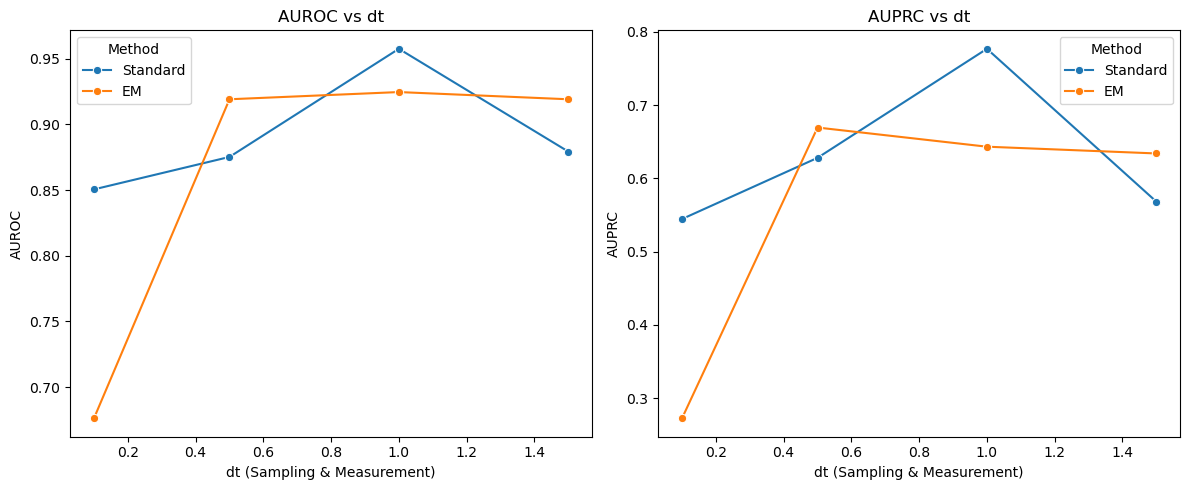

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/likelihood_benchmark_results.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.lineplot(data=df, x='dt', y='AUROC', hue='Method', marker='o', ax=axes[0])
axes[0].set_title('AUROC vs dt')
axes[0].set_xlabel('dt (Sampling & Measurement)')
axes[0].set_ylabel('AUROC')

sns.lineplot(data=df, x='dt', y='AUPRC', hue='Method', marker='o', ax=axes[1])
axes[1].set_title('AUPRC vs dt')
axes[1].set_xlabel('dt (Sampling & Measurement)')
axes[1].set_ylabel('AUPRC')

plt.tight_layout()
plt.show()

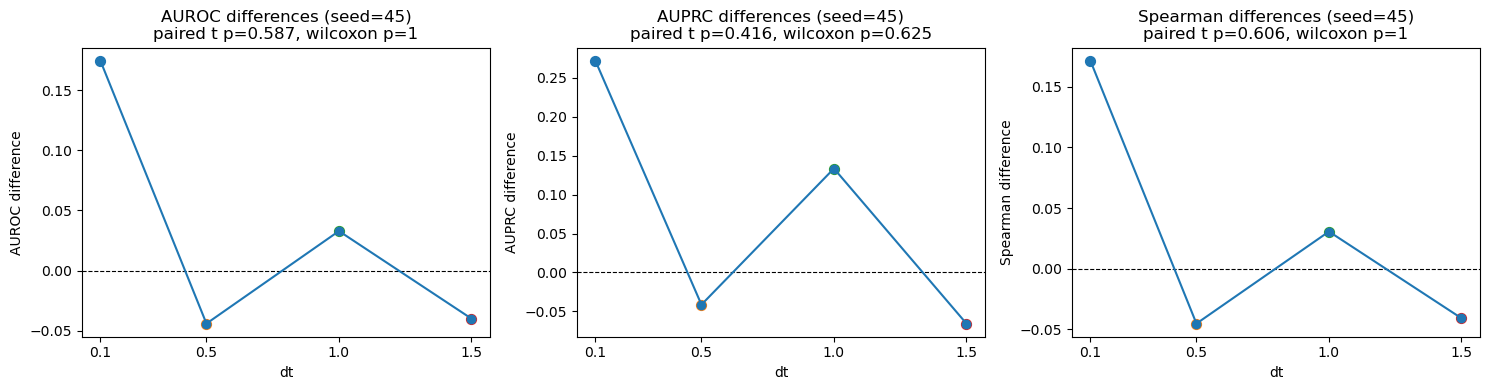

In [17]:
from scipy.stats import ttest_rel, wilcoxon

metrics = ['AUROC', 'AUPRC', 'Spearman']
seeds = sorted(df['Seed'].unique())

for seed in seeds:
    se = df[df['Seed'] == seed].copy()
    dts = sorted(se['dt'].unique())
    fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4), sharey=False)
    if len(metrics) == 1:
        axes = [axes]
    for ax, metric in zip(axes, metrics):
        std_vals = se[(se['Method'] == 'Standard')].set_index('dt').loc[dts][metric].values
        em_vals = se[(se['Method'] == 'EM')].set_index('dt').loc[dts][metric].values
        # paired tests
        t_stat, p_t = ttest_rel(std_vals, em_vals)
        p_w = None
        try:
            w_stat, p_w = wilcoxon(std_vals, em_vals)
        except Exception:
            p_w = np.nan
        diffs = std_vals - em_vals
        ax.axhline(0, color='k', linestyle='--', linewidth=0.8)
        ax.plot(dts, diffs, marker='o', linestyle='-', label='Std - EM')
        ax.set_xlabel('dt')
        ax.set_xticks(dts)
        ax.set_title(f'{metric} differences (seed={seed})\npaired t p={p_t:.3g}, wilcoxon p={np.nan if np.isnan(p_w) else f"{p_w:.3g}"}')
        ax.set_ylabel(f'{metric} difference')
        # show individual points
        for x, y in zip(dts, diffs):
            ax.scatter(x, y, s=50)
    plt.tight_layout()
    plt.show()